<a href="https://colab.research.google.com/github/Kuper994/Software-Project/blob/main/scikit_learn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning

Last weeks we focused on: preprocessing, visualization & analysis

Today: ML

We are given a dataset and would like to perform a task with it.

## Basic Example - House Price Prediction
Given: a dataset of N samples
$(x_1,y_1),...(x_n,y_n)$

$x - square$

$y - price$

Task: what is the price of house that has $x$ square ?

### One dimensional

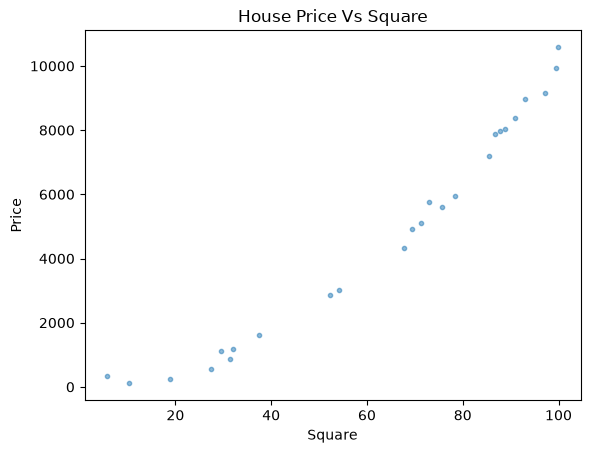

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(162)
# Create data
N = 25
x = np.random.rand(N)*100
y = x**2 + np.random.normal(1,2,size=N)*100
colors = (0,0,0)
area = np.pi*3

# Plot
plt.scatter(x, y, s=area, alpha=0.5)
plt.title('House Price Vs Square')
plt.xlabel('Square')
plt.ylabel('Price')
plt.show()

$x=60$ ?

### More Features
Now what if we know the age of the house ?

$(age,square)\rightarrow price$

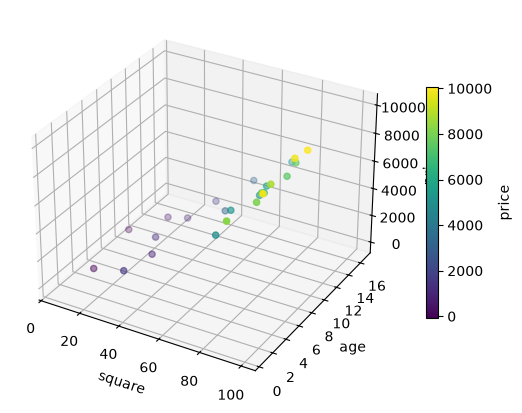

In [2]:
# Create data
np.random.seed(162)
N = 25
x = np.random.rand(N)*100
age = np.random.rand(N)*18
y = x**2 + 0.5*age + np.random.normal(1,2,size=N)*100

# 3-D scatter plot with matplotlib
fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(projection='3d')
points = ax.scatter(x, age, y, c=y)
ax.set_xlabel('square')
ax.set_ylabel('age')
ax.set_zlabel('price')
fig.colorbar(points, label='price', shrink=0.6)
plt.show()

### High Dimensional Features
$x\in R^d$

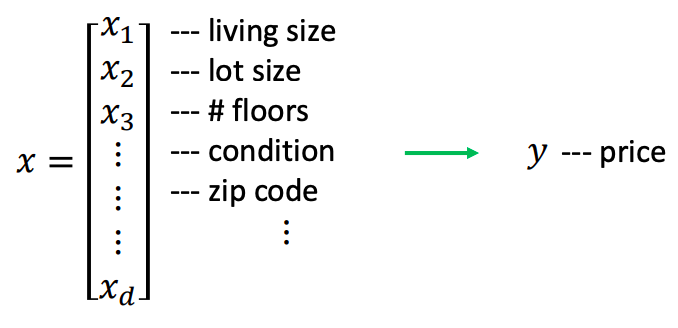

## Classical ML

![img](https://i.vas3k.ru/7w1.jpg )
<!-- <img src="https://i.vas3k.ru/7w1.jpg" width="600" height="600" /> -->




*The illustrations in this section are from Vasily Zubarev, [Machine Learning for Everyone](https://vas3k.com/blog/machine_learning/).*

### Supervised

#### Classification
Today used for:
* Spam filtering
* Language detection
* Sentiment analysis
* Recognition of handwritten characters and numbers
* Fraud detection

Popular algorithms: Naive Bayes, Decision Tree, Logistic Regression, K-Nearest Neighbours, Support Vector Machine, DNN (Deep Neural Networks)

![](https://i.vas3k.ru/7qx.jpg)

![](https://i.vas3k.ru/7w3.jpg)

Image Classification (CIFAR10 dataset)

![](https://pytorch.org/tutorials/_images/cifar10.png)


#### Regression

Today this is used for:

* Stock price forecasts
* Demand and sales volume analysis
* Medical diagnosis
* Any number-time correlations

![](https://i.vas3k.ru/7qy.jpg)

![](https://i.vas3k.ru/7w5.jpg)

### Unsupervised

#### Clustering
Nowadays used:

* For market segmentation (types of customers, loyalty)
* To merge close points on a map
* To analyze and label new data
* To detect abnormal behavior

![](https://i.vas3k.ru/7qz.jpg)

#### Dimensionality Reduction
Used for:
* Recommender systems
* Beautiful visualizations
* Topic modeling and similar document search
* Fake image analysis
* signal analysis

![](https://i.vas3k.ru/7r0.jpg)

Popular algorithms: Principal Component Analysis (PCA), Singular Value Decomposition (SVD), Latent Dirichlet allocation (LDA), Latent Semantic Analysis (LSA, pLSA, GLSA), t-SNE (for visualization)

# scikit-learn

[Scikit-learn](https://scikit-learn.org/stable/) is a library that allows you to do machine learning, that is, make predictions from data, in Python. There are four basic machine learning tasks:

 1. Regression: predict a number from datapoints, given datapoints and corresponding numbers
 2. Classification: predict a category from datapoints, given datapoints and corresponding numbers
 3. Clustering: predict a category from datapoints, given only datapoints
 4. Dimensionality reduction: make datapoints lower-dimensional so that we can visualize the data

[![Choosing the right estimator](https://scikit-learn.org/stable/_static/ml_map.svg)](https://scikit-learn.org/stable/machine_learning_map.html)

*Source: scikit-learn, [Choosing the right estimator](https://scikit-learn.org/stable/machine_learning_map.html).*

## Scikit-learn: theory

*   Comprehensive library for machine learning
*   Computation pipeline is as follows:
  *   Choose model
  *   Select model’s hyper-parameters
  *   Arrange data into feature matrix + target vector
  *   Fit the model to data using the fit() method
  *   Predict labels for unknown data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets

## Regression

In [4]:
diabetes = datasets.load_diabetes()

In [5]:
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [6]:
df_diabetes = pd.DataFrame(diabetes.data,columns=diabetes.feature_names)
df_diabetes['target'] = pd.Series(diabetes.target)
df_diabetes.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


<Axes: ylabel='Frequency'>

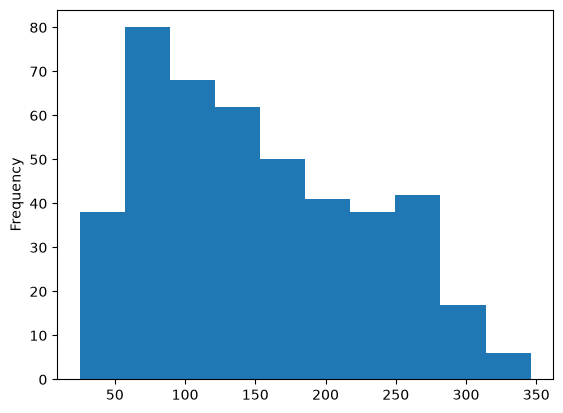

In [7]:
df_diabetes['target'].plot(kind='hist')

<Axes: xlabel='bmi', ylabel='target'>

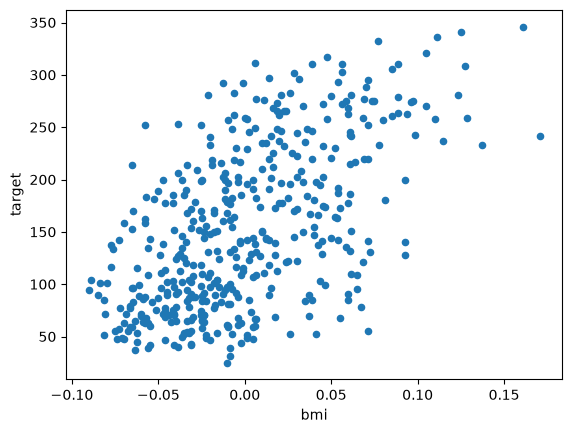

In [8]:
df_diabetes.plot('bmi', 'target', kind='scatter')

In [9]:
X = diabetes.data[:,[2]]
Y = diabetes.target

In [10]:
X = df_diabetes[['bmi']].to_numpy()
y = df_diabetes['target'].to_numpy()

In [11]:
from sklearn import linear_model
model = linear_model.LinearRegression()
model.fit(X, Y)
print(model.coef_, model.intercept_)

[949.43526038] 152.13348416289617


In [12]:
print(model.score(X, Y))

0.3439237602253802


In [13]:
model.predict(np.array([[0.05], [-0.02]]))

array([199.60524718, 133.14477896])

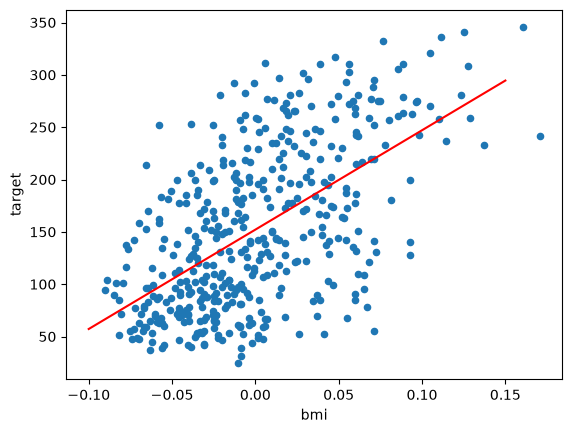

In [14]:
df_diabetes.plot('bmi', 'target', kind='scatter')

bmi = np.linspace(-0.1, 0.15, 20).reshape(-1, 1)
plt.plot(bmi, model.predict(bmi), 'r')

## Classification

Another example of a machine learning problem is classification. Here we will use a dataset of flower measurements from three different flower species of *Iris* (*Iris setosa*, *Iris virginica*, and *Iris versicolor*). We aim to predict the species of the flower. Because the species is not a numerical output, it is not a regression problem, but a classification problem.

In [15]:
from sklearn import datasets
iris = datasets.load_iris()
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [16]:
X = iris.data[:, :2]
y = iris.target_names[iris.target]

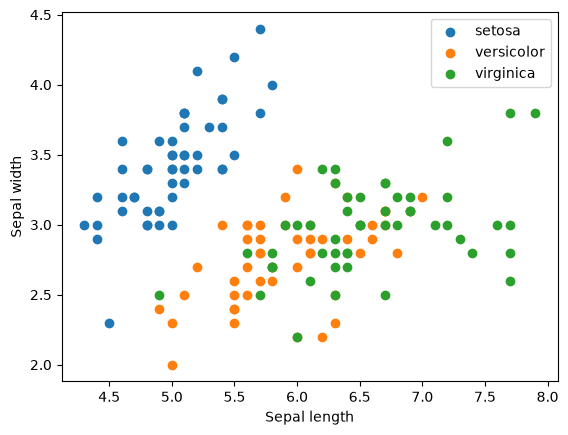

In [17]:
for name in iris.target_names:
    plt.scatter(X[y == name, 0], X[y == name, 1], label=name)
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')
plt.legend();

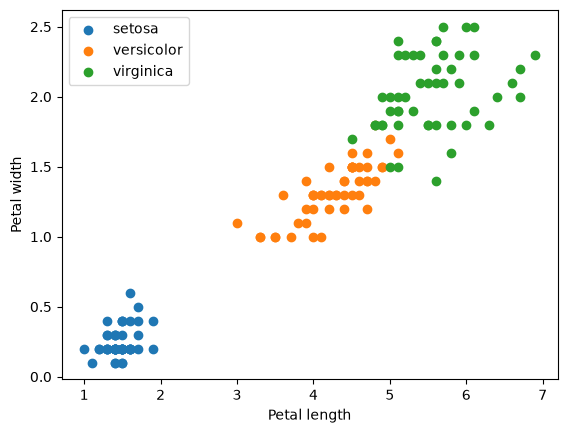

In [18]:
X = iris.data[:, 2:]
y = iris.target_names[iris.target]
for name in iris.target_names:
    plt.scatter(X[y == name, 0], X[y == name, 1], label=name)
plt.xlabel('Petal length')
plt.ylabel('Petal width')
plt.legend();

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(120, 2) (120,)
(30, 2) (30,)


In [20]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(5)
model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[<U10](3,)","['setosa','versicolor','virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [21]:
model.predict(X_test)

array(['virginica', 'versicolor', 'setosa', 'virginica', 'setosa',
       'virginica', 'setosa', 'versicolor', 'versicolor', 'versicolor',
       'virginica', 'versicolor', 'versicolor', 'versicolor',
       'versicolor', 'setosa', 'versicolor', 'versicolor', 'setosa',
       'setosa', 'virginica', 'versicolor', 'setosa', 'setosa',
       'virginica', 'setosa', 'setosa', 'versicolor', 'versicolor',
       'setosa'], dtype='<U10')

### Evaluating your model

In [22]:
np.mean(model.predict(X_test) == y_test)  # Accuracy

np.float64(1.0)

NumPy 2 prints a scalar together with its type, for example `np.float64(1.0)`. The value is simply the number 1.0; `print()` or an f-string shows it without the type.

In [23]:
import sklearn.metrics as metrics
metrics.accuracy_score(y_test, model.predict(X_test))   # (y_true, y_pred)

1.0

In [24]:
y_pred = model.predict(X_test)
# The order matters: classification_report(y_true, y_pred).
# Swapping them exchanges precision and recall, and "support" counts the predictions instead of the true labels.
print(metrics.classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        11
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00         6

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



![Precision and recall](img/Precisionrecall.svg)

*Image: Walber, [Precisionrecall.svg](https://commons.wikimedia.org/wiki/File:Precisionrecall.svg), CC BY-SA 4.0, via Wikimedia Commons.*

In [25]:
# Cross validation
from sklearn.model_selection import cross_val_score
model = KNeighborsClassifier()
scores = cross_val_score(model, X, y, cv=5)
scores

array([0.96666667, 0.96666667, 0.93333333, 0.96666667, 1.        ])

In [26]:
print(f"Accuracy: {scores.mean()} (+/- {scores.std()})")

Accuracy: 0.9666666666666668 (+/- 0.02108185106778919)


## Clustering

Clustering is useful if we don't have a dataset labelled with the categories we want to predict, but we nevertheless expect there to be a certain number of categories. For example, suppose we have the previous dataset, but we are missing the labels. We can use a clustering algorithm like k-means to *cluster* the datapoints. Because we don't have labels, clustering is what is called an **unsupervised learning** algorithm.

In [27]:
X = iris.data

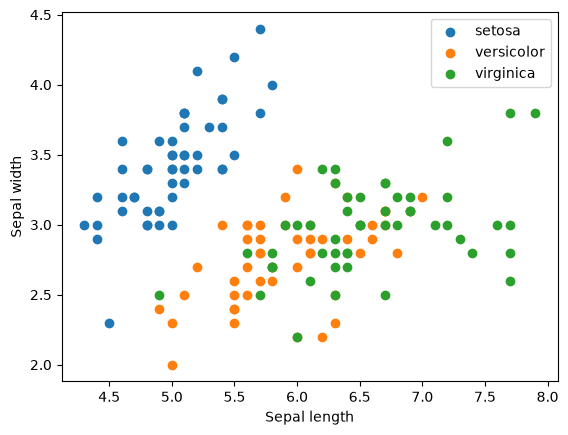

In [28]:
for name in iris.target_names:
    plt.scatter(X[y == name, 0], X[y == name, 1], label=name)
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')
plt.legend()
plt.show()

In [29]:
from sklearn.cluster import KMeans

model = KMeans(n_clusters=3, random_state=0)
model.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 4)","[[

In [30]:
model.labels_

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 2, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 0, 0, 2, 2, 2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 0, 2, 2, 2, 2,
       2, 0, 2, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 2, 0], dtype=int32)

In [31]:
iris.target

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

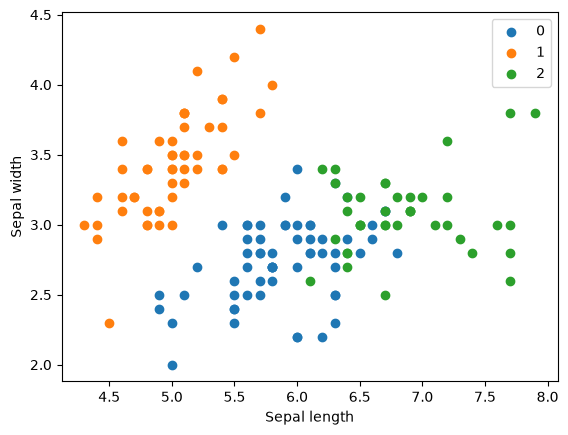

In [32]:
for name in [0,1,2]:
    plt.scatter(X[model.labels_ == name, 0], X[model.labels_ == name, 1], label=name)
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')
plt.legend()
plt.show()

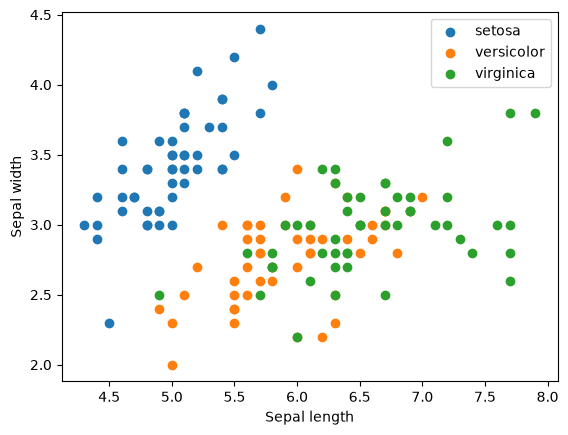

In [33]:
for name in iris.target_names:
    plt.scatter(X[y == name, 0], X[y == name, 1], label=name)
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')
plt.legend()
plt.show()

## Dimensionality reduction (PCA)

Dimensionality reduction is another unsupervised learning problem (that is, it does not require labels). It aims to project datapoints into a lower dimensional space while preserving distances between datapoints.

Lets take a look at the breast cancer dataset with dimensionality reduction

In [34]:
bc = datasets.load_breast_cancer()

In [35]:
print(bc.DESCR)

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [36]:
X = bc.data
y = bc.target_names[bc.target]

In [37]:
bc.feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

For the **picture** below we scale and project all samples: this is unsupervised visualisation, no model is evaluated.

In [38]:
from sklearn.preprocessing import StandardScaler
X = StandardScaler().fit_transform(X) # normalizing the features

In [39]:
np.mean(X,axis=0),np.std(X,axis=0)

(array([-3.16286735e-15, -6.53060890e-15, -7.07889127e-16, -8.79983452e-16,
         6.13217737e-15, -1.12036918e-15, -4.42138027e-16,  9.73249991e-16,
        -1.97167024e-15, -1.45363120e-15, -9.07641468e-16, -8.85349205e-16,
         1.77367396e-15, -8.29155139e-16, -7.54180940e-16, -3.92187747e-16,
         7.91789988e-16, -2.73946068e-16, -3.10823423e-16, -3.36676596e-16,
        -2.33322442e-15,  1.76367415e-15, -1.19802625e-15,  5.04966114e-16,
        -5.21317026e-15, -2.17478837e-15,  6.85645643e-16, -1.41265636e-16,
        -2.28956670e-15,  2.57517109e-15]),
 array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]))

In [40]:
from sklearn.decomposition import PCA
pca_breast = PCA(n_components=2)
X_PCA = pca_breast.fit_transform(X)

In [41]:
pd.DataFrame(data = X_PCA, columns = ['pc_1', 'pc_2'])

,pc_1,pc_2
0,9.192837,1.948583
1,2.387802,-3.768172
2,5.733896,-1.075174
3,7.122953,10.275589
4,3.935302,-1.948072
...,...,...
564,6.439315,-3.576817
565,3.793382,-3.584048
566,1.256179,-1.902297
567,10.374794,1.672010


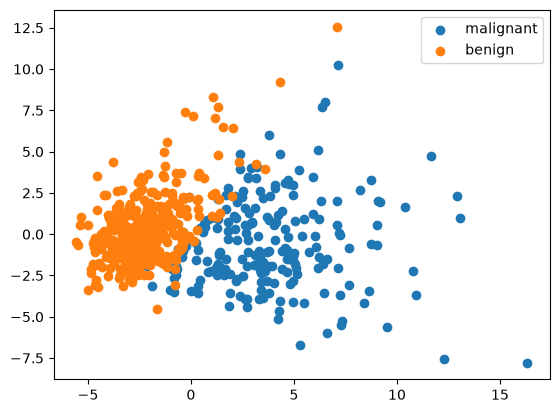

In [42]:
for name in bc.target_names:
    plt.scatter(X_PCA[y == name, 0], X_PCA[y == name, 1], label=name)
plt.legend()

### Training a classifier without data leakage

The scaler and PCA above were fit on **all** samples, which is fine for a picture. For a model we evaluate, every step must be fit on the **training set only**; otherwise information from the test set leaks into training and the score is too optimistic.
A `Pipeline` chains the steps and guarantees that `fit` only ever sees the training data. So we split the raw, unscaled features first:

accuracy: 0.8936170212765957


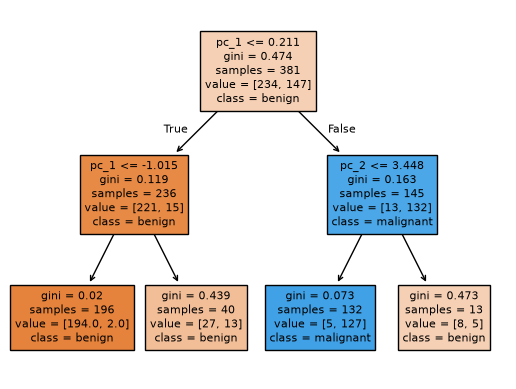

In [43]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn import tree

X_raw = bc.data   # original, unscaled features
x_train, x_test, y_train, y_test = train_test_split(X_raw, y, test_size=0.33, random_state=1)

clf = make_pipeline(StandardScaler(), PCA(n_components=2), tree.DecisionTreeClassifier(max_depth=2))
clf.fit(x_train, y_train)   # scaler, PCA and tree are fit on the training set only
print('accuracy:', clf.score(x_test, y_test))
tree.plot_tree(clf[-1], feature_names=['pc_1', 'pc_2'], class_names=list(clf.classes_), filled=True);

How balanced are the classes in the training set? A classifier that always predicts the majority class would already reach the larger fraction, so the tree's accuracy should be compared with it.

In [44]:
pd.Series(y_train).value_counts(normalize=True)

benign       0.614173
malignant    0.385827
Name: proportion, dtype: float64